In [7]:
import numpy as np
import scipy
from planck_lite_py import PlanckLitePy
from matplotlib import pyplot as plt

import os
import camb
from camb import initialpower, model

print(f"Using CAMB {camb.__version__} installed at {os.path.dirname(camb.__file__)}")


Using CAMB 2.0.5 installed at c:\Users\irisr\anaconda3\envs\NN\Lib\site-packages\camb


In [ ]:
# https://github.com/heatherprince/planck-lite-py

data_path = "C:/Users/irisr/OneDrive/Documents/GitHub/COMP2026/agentic/08_optimization/data/"

TT2018 = PlanckLitePy(data_directory=data_path, year=2018, spectra='TTTEEE', use_low_ell_bins=False)

# calculate theoretical TT, TE, and EE spectra with CAMB
# then get the log likelihood by running this:
# loglike=TT2018.loglike(Dltt, Dlte, Dlee, ellmin) 

just copying the tutorial notebook to see that package works

total
unlensed_scalar
unlensed_total
lensed_scalar
tensor
lens_potential
(3051, 4)


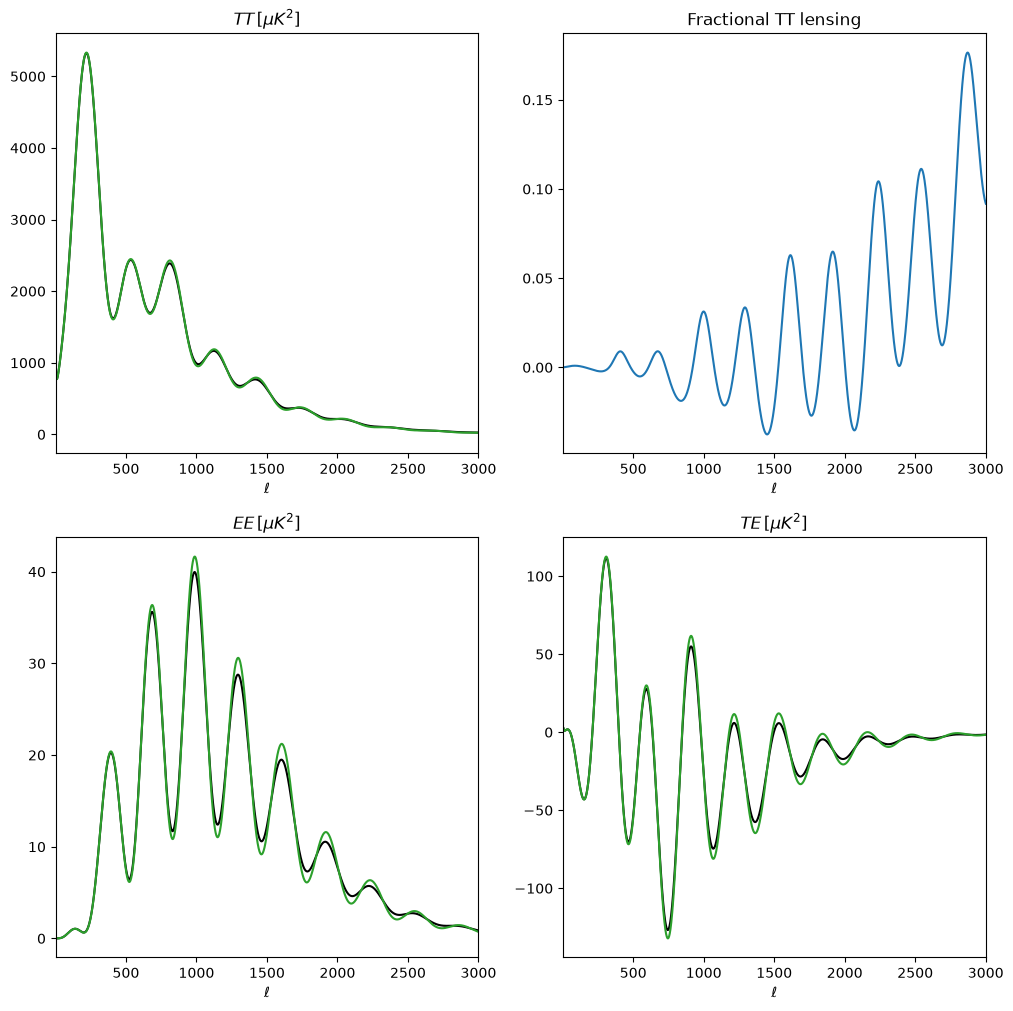

In [9]:
pars = camb.set_params(
    H0=67.5, ombh2=0.022, omch2=0.122, mnu=0.06, omk=0, tau=0.06, As=2e-9, ns=0.965, halofit_version="mead", lmax=3000
)

results = camb.get_results(pars)

powers = results.get_cmb_power_spectra(pars, CMB_unit="muK")
for name in powers:
    print(name)

# plot the total lensed CMB power spectra versus unlensed, and fractional difference
totCL = powers["total"]
unlensedCL = powers["unlensed_scalar"]
print(totCL.shape)
# Python CL arrays are all zero based (starting at L=0), Note L=0,1 entries will be zero by default.
# The different CL are always in the order TT, EE, BB, TE (with BB=0 for unlensed scalar results).
ls = np.arange(totCL.shape[0])
fig, ax = plt.subplots(2, 2, figsize=(12, 12))
ax[0, 0].plot(ls, totCL[:, 0], color="k")
ax[0, 0].plot(ls, unlensedCL[:, 0], color="C2")
ax[0, 0].set_title(r"$TT\, [\mu K^2]$")
ax[0, 1].plot(ls[2:], 1 - unlensedCL[2:, 0] / totCL[2:, 0])
ax[0, 1].set_title(r"Fractional TT lensing")
ax[1, 0].plot(ls, totCL[:, 1], color="k")
ax[1, 0].plot(ls, unlensedCL[:, 1], color="C2")
ax[1, 0].set_title(r"$EE\, [\mu K^2]$")
ax[1, 1].plot(ls, totCL[:, 3], color="k")
ax[1, 1].plot(ls, unlensedCL[:, 3], color="C2")
ax[1, 1].set_title(r"$TE\, [\mu K^2]$")
for ax in ax.reshape(-1):
    ax.set_xlim([2, 3000])
    ax.set_xlabel(r"$\ell$")


data downloaded from https://pla.esac.esa.int/#cosmology